# 01 - Normal bivariante: Isolation Forest vs. Halfspace Depth

En este cuaderno compararemos sobre datos de una distribución normal bivariante, la anomaly score
$s(\mathbf{x},\psi)$ del algoritmo de Isolation Forest con la profundidad de semiespacios $HD(\mathbf{x},P_n)$.

- $s(\mathbf{x},\psi)$ se calcula usando nuestra implementación de Liu et al. (2012), `src/isolation_forest.py`.
- $HD(\mathbf{x},P_n)$ se calcula de forma exacta (en dimensión 2) con la librería `data-depth`. Fuente: https://data-depth.github.io/auto_examples/plot_halfDepth.html

In [73]:
import sys
import random

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.stats import chi2, norm, spearmanr

from sklearn.ensemble import IsolationForest

sys.path.append("../src")
import torch_error
from depth.model.DepthEucl import DepthEucl
from isolation_forest import iforest, itree, path_length, anomaly_score, c

## Ejemplo 1 - Normal bivariante con baja correlación

Generamos $n = 500$ observaciones de una normal bivariante $N_2(\boldsymbol{\mu}, \Sigma)$ con
$$
\boldsymbol{\mu} = \begin{pmatrix} 1 \\ -0.5 \end{pmatrix}, \qquad
\Sigma = \begin{pmatrix} 1.5 & 0.3 \\ 0.3 & 1 \end{pmatrix},
$$
es decir, varianzas $1.5$ y $1$ y correlación $0.3/\sqrt{1.5} \approx 0.24$. La nube es ligeramente
alargada e inclinada, pero sin una correlación fuerte. No añadimos anomalías: las observaciones
atípicas son simplemente las de la cola de la normal.

Para seguir dos observaciones concretas a lo largo del cuaderno elegimos, con la distancia de
Mahalanobis $d_M(\mathbf{x}) = \sqrt{(\mathbf{x}-\boldsymbol{\mu})^T \Sigma^{-1} (\mathbf{x}-\boldsymbol{\mu})}$,
la observación más central de la muestra, $\mathbf{x}_i$, y la más alejada, $\mathbf{x}_o$.

In [74]:
def distancia_mahalanobis(X, mu, Sigma):
    Z = X - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", Z, np.linalg.inv(Sigma), Z))

In [75]:
mu = np.array([1.0, -0.5])
Sigma = np.array([[1.5, 0.3],
                  [0.3, 1.0]])
n = 500

rng = np.random.default_rng(2026)
datos = rng.multivariate_normal(mu, Sigma, size=n)

correlacion = Sigma[0, 1] / np.sqrt(Sigma[0, 0] * Sigma[1, 1])
print(f"Correlación: {correlacion:.3f}")

d_M = distancia_mahalanobis(datos, mu, Sigma)
i_central, i_atipico = np.argmin(d_M), np.argmax(d_M)
x_i, x_o = datos[i_central], datos[i_atipico]

print(f"Observación más central x_i = ({x_i[0]:.2f}, {x_i[1]:.2f}),  d_M = {d_M[i_central]:.2f}")
print(f"Observación más alejada x_o = ({x_o[0]:.2f}, {x_o[1]:.2f}),  d_M = {d_M[i_atipico]:.2f}")

Correlación: 0.245
Observación más central x_i = (0.90, -0.48),  d_M = 0.09
Observación más alejada x_o = (-3.21, 0.75),  d_M = 4.06


Representamos ahora la muestra junto con las elipses de la densidad teórica que contienen el $50\,\%$,
$90\,\%$ y $99\,\%$ de la probabilidad. Como $d_M(\mathbf{X})^2 \sim \chi^2_2$, cada elipse es el conjunto
$\{\mathbf{x} : d_M(\mathbf{x})^2 = \chi^2_{2,\alpha}\}$.

In [76]:
def elipse(nivel, num=200):
    # Puntos de la elipse d_M(x)^2 = chi2_{2, nivel}: mu + r * Sigma^{1/2} (cos t, sin t)
    r = np.sqrt(chi2.ppf(nivel, df=2))
    valores, vectores = np.linalg.eigh(Sigma)
    raiz = vectores @ np.diag(np.sqrt(valores)) @ vectores.T
    t = np.linspace(0, 2 * np.pi, num)
    return mu + r * (raiz @ np.vstack([np.cos(t), np.sin(t)])).T

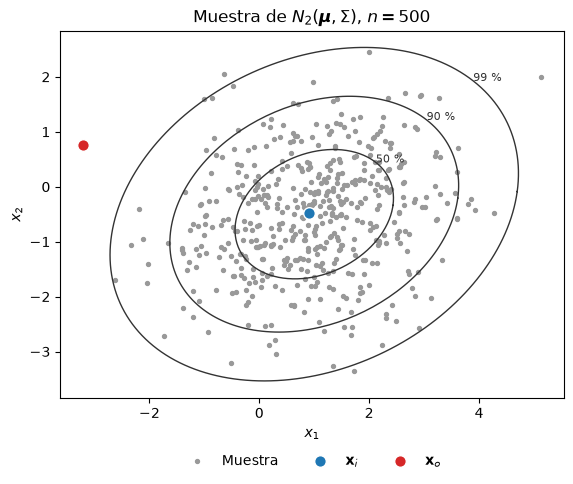

In [77]:
fig, eje = plt.subplots(figsize=(6.5, 5))
eje.scatter(datos[:, 0], datos[:, 1], s=8, c="0.6", label="Muestra")
for nivel in (0.5, 0.9, 0.99):
    e = elipse(nivel)
    eje.plot(e[:, 0], e[:, 1], color="0.2", linewidth=1)
    eje.annotate(f"{int(nivel * 100)} %", e[25], fontsize=8, color="0.2")
eje.scatter(*x_i, s=70, c="tab:blue", edgecolors="white", zorder=3, label=r"$\mathbf{x}_i$")
eje.scatter(*x_o, s=70, c="tab:red", edgecolors="white", zorder=3, label=r"$\mathbf{x}_o$")
eje.set_xlabel("$x_1$")
eje.set_ylabel("$x_2$")
eje.set_title(r"Muestra de $N_2(\boldsymbol{\mu}, \Sigma)$, $n = 500$")
eje.set_aspect("equal")
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.savefig("../figures/01.1_datos.pdf", bbox_inches="tight")
plt.show()

### Métricas del Isolation Forest

Construimos un único árbol de aislamiento sobre una submuestra de tamaño $\psi = 256$. Para poder ver cómo se aíslan $\mathbf{x}_i$ y $\mathbf{x}_o$, la submuestra está formada por estas dos
observaciones y 254 más elegidas al azar entre el resto.

Cada nodo interno del árbol corta el plano con una recta paralela a uno de los ejes. Recorriendo el árbol con una observación $\mathbf{x}$, los cortes que atraviesa delimitan rectángulos cada vez
más pequeños hasta que $\mathbf{x}$ queda sola en el suyo. Como el árbol está construido completo y las observaciones son distintas, el número de cortes coincide con $h(\mathbf{x})$, porque $c(1) = 0$.

In [78]:
def recorrido(x, T, caja):
    # Baja por el árbol T con la observación x y guarda cada corte (q, p) junto con
    # el rectángulo que había antes de cortar. Devuelve también el rectángulo final.
    caja = [list(limites) for limites in caja]
    cortes = []
    while "q" in T:
        q, p = T["q"], T["p"]
        cortes.append((q, p, [list(limites) for limites in caja]))
        if x[q] < p:
            caja[q][1] = p
            T = T["izq"]
        else:
            caja[q][0] = p
            T = T["der"]
    return cortes, caja


def dibujar_recorrido(eje, x, color, titulo):
    sub = np.array(submuestra)
    caja0 = [[sub[:, 0].min() - 0.3, sub[:, 0].max() + 0.3],
             [sub[:, 1].min() - 0.3, sub[:, 1].max() + 0.3]]
    cortes, caja_final = recorrido(x, arbol, caja0)

    eje.scatter(sub[:, 0], sub[:, 1], s=10, facecolors="none", edgecolors="0.5")
    for q, p, caja in cortes:
        if q == 0:   # corte en x_1: recta vertical dentro del rectángulo actual
            eje.plot([p, p], caja[1], color="black", linewidth=0.9)
        else:        # corte en x_2: recta horizontal
            eje.plot(caja[0], [p, p], color="black", linewidth=0.9)
    (a1, b1), (a2, b2) = caja_final
    eje.add_patch(Rectangle((a1, a2), b1 - a1, b2 - a2, color=color, alpha=0.25))
    eje.scatter(*x, s=60, c=color, edgecolors="white", zorder=3)
    eje.set_xlim(caja0[0])
    eje.set_ylim(caja0[1])
    eje.set_title(f"{titulo}: {len(cortes)} cortes")
    eje.set_xlabel("$x_1$")
    return len(cortes)

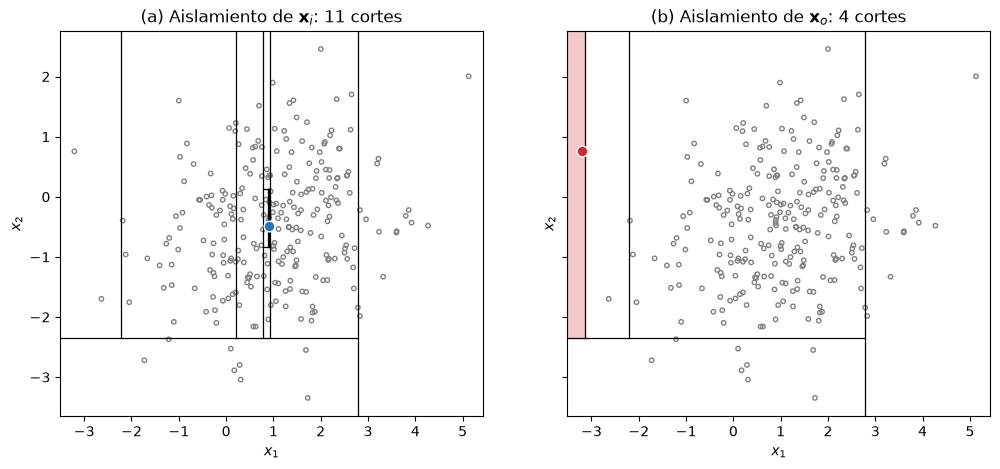

In [79]:
random.seed(5)
resto = [list(x) for k, x in enumerate(datos) if k not in (i_central, i_atipico)]
submuestra = random.sample(resto, 254) + [list(x_i), list(x_o)]
arbol = itree(submuestra)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
h_i_arbol = dibujar_recorrido(ejes[0], x_i, "tab:blue", r"(a) Aislamiento de $\mathbf{x}_i$")
h_o_arbol = dibujar_recorrido(ejes[1], x_o, "tab:red", r"(b) Aislamiento de $\mathbf{x}_o$")
ejes[0].set_ylabel("$x_2$")
ejes[1].set_ylabel("$x_2$")
plt.savefig("../figures/01.1_aislamiento_itree.pdf", bbox_inches="tight")
plt.show()

El problema se encuentra en que un único árbol es muy variable. La puntuación de anomalía usa $E(h(\mathbf{x}))$, que estimamos con la media de
$h(\mathbf{x})$ sobre $t$ árboles independientes. Construimos un bosque de $t = 1000$ árboles y representamos la media acumulada de $h(\mathbf{x}_i)$ y $h(\mathbf{x}_o)$ en función
del número de árboles, en escala logarítmica.

En el resto del cuaderno usamos los 100 primeros árboles, que forman por sí mismos un bosque con
$t = 100$. El límite de altura será el valor por defecto, $h_{lim} = \psi - 1 = 255$.

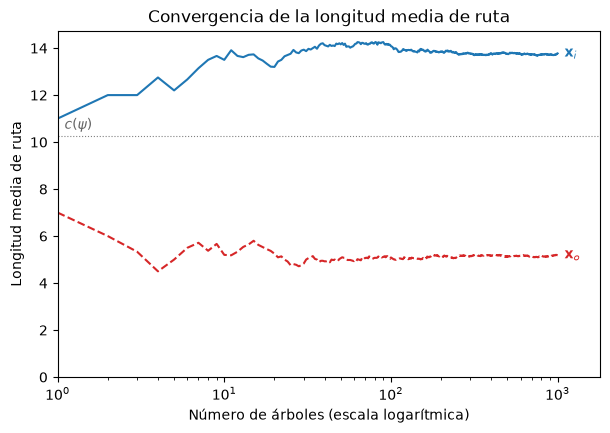

E(h(x_i)) con 1000 árboles: 13.78 (con 100 árboles: 14.08)
E(h(x_o)) con 1000 árboles: 5.19 (con 100 árboles: 5.09)


In [80]:
random.seed(105)
psi, hlim = 256, 255
bosque_grande = iforest(datos.tolist(), t=1000, psi=psi)
bosque = bosque_grande[:100]

h_i = np.array([path_length(list(x_i), T, hlim) for T in bosque_grande])
h_o = np.array([path_length(list(x_o), T, hlim) for T in bosque_grande])
num_arboles = np.arange(1, 1001)

fig, eje = plt.subplots(figsize=(7, 4.5))
eje.plot(num_arboles, np.cumsum(h_i) / num_arboles, color="tab:blue", linewidth=1.5)
eje.plot(num_arboles, np.cumsum(h_o) / num_arboles, color="tab:red", linewidth=1.5, linestyle="--")
eje.annotate(r"$\mathbf{x}_i$", (1100, h_i.mean()), color="tab:blue", va="center")
eje.annotate(r"$\mathbf{x}_o$", (1100, h_o.mean()), color="tab:red", va="center")
eje.axhline(c(psi), color="0.5", linewidth=0.8, linestyle=":")
eje.annotate(r"$c(\psi)$", (1.1, c(psi) + 0.3), color="0.4")
eje.set_xscale("log")
eje.set_xlim(1, 1800)
eje.set_ylim(0, None)
eje.set_xlabel("Número de árboles (escala logarítmica)")
eje.set_ylabel("Longitud media de ruta")
eje.set_title("Convergencia de la longitud media de ruta")
plt.savefig("../figures/01.1_convergencia.pdf", bbox_inches="tight")
plt.show()

print(f"E(h(x_i)) con 1000 árboles: {h_i.mean():.2f} (con 100 árboles: {h_i[:100].mean():.2f})")
print(f"E(h(x_o)) con 1000 árboles: {h_o.mean():.2f} (con 100 árboles: {h_o[:100].mean():.2f})")

Calculemos ahora el **anomaly_score**, que es una función decreciente de $E(h(\mathbf{x}))$:
$$
s(\mathbf{x},\psi) = 2^{-E(h(\mathbf{x}))/c(\psi)},
$$
que vale $1$ si $E(h(\mathbf{x})) \to 0$, $0.5$ si $E(h(\mathbf{x})) = c(\psi)$ y tiende a $0$ cuando
$E(h(\mathbf{x})) \to \psi - 1$. Dibujamos la curva para varios valores de $\psi$ y situamos sobre la de $\psi = 256$ las 500 observaciones de la muestra.

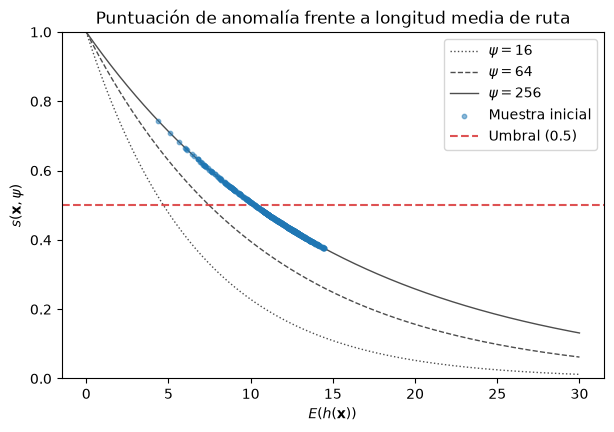

In [81]:
def longitud_media(x, bosque, hlim):
    return sum(path_length(x, T, hlim) for T in bosque) / len(bosque)

E_h = np.array([longitud_media(list(x), bosque, hlim) for x in datos])
s_datos = 2 ** (-E_h / c(psi))

fig, eje = plt.subplots(figsize=(7, 4.5))
E = np.linspace(0, 30, 300)
for psi_, estilo in ((16, ":"), (64, "--"), (256, "-")):
    eje.plot(E, 2 ** (-E / c(psi_)), color="0.3", linestyle=estilo, linewidth=1, label=rf"$\psi = {psi_}$")
eje.scatter(E_h, s_datos, s=10, c="tab:blue", alpha=0.5, zorder=3, label="Muestra inicial")
eje.axhline(0.5, color="tab:red", linestyle="--", linewidth=1.5, alpha=0.8, zorder=2, label="Umbral (0.5)")
eje.set_xlabel(r"$E(h(\mathbf{x}))$")
eje.set_ylabel(r"$s(\mathbf{x}, \psi)$")
eje.set_ylim(0, 1)
eje.set_title("Puntuación de anomalía frente a longitud media de ruta")
eje.legend()
plt.savefig("../figures/01.1_s_frente_Eh.pdf", bbox_inches="tight")
plt.show()

### Cálculo de la profundidad de Tukey

Cargamos la muestra en `DepthEucl` y calculamos $HD(\mathbf{x},P_n)$ de forma exacta
(`exact=True`) para los mismos puntos. $HD$ toma valores en $\{0, 1/n, \dots\}$
y que vale $0$ fuera de la envolvente convexa de la muestra.

In [82]:
modelo = DepthEucl().load_dataset(datos)
hd_datos = modelo.halfspace(datos, exact=True)

print(f"HD en la muestra: mínimo {hd_datos.min():.3f}, máximo {hd_datos.max():.3f}")
print(f"HD(x_i) = {hd_datos[i_central]:.3f},  s(x_i) = {s_datos[i_central]:.3f}")
print(f"HD(x_o) = {hd_datos[i_atipico]:.3f},  s(x_o) = {s_datos[i_atipico]:.3f}")

HD en la muestra: mínimo 0.002, máximo 0.454
HD(x_i) = 0.454,  s(x_i) = 0.386
HD(x_o) = 0.002,  s(x_o) = 0.709


### Comparación iForest vs. Halfspace Depth

Para comparar ambos métodos definimos tres funciones que usaremos también en el Ejemplo 2:

- `dibujar_mapas`: cada observación coloreada según $s(\mathbf{x},\psi)$ (más oscuro, más anómala) y
  según $HD(\mathbf{x},P_n)$ (más oscuro, más profunda). Si la hipótesis se cumple, los dos mapas
  deberían ser aproximadamente complementarios.
- `dibujar_s_frente_hd`: $s$ frente a $HD$ junto con la correlación de Spearman $\rho_S$, que solo
  depende del orden. Bajo la hipótesis esperamos $\rho_S$ próxima a $-1$. La recta discontinua marca
  $s = 0.5$, el valor que corresponde a $E(h(\mathbf{x})) = c(\psi)$.
- `anomalias_comunes`: marca como anómalo el $5\,\%$ de la muestra según cada método (las de mayor
  $s$ y las de menor $HD$) y cuenta cuántas coinciden. Como $HD$ es discreta puede haber empates en
  el corte; en ese caso `argsort` elige entre las empatadas por orden de aparición.

In [83]:
def dibujar_mapas(datos, s, hd, archivo):
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

    p0 = ejes[0].scatter(datos[:, 0], datos[:, 1], c=s, cmap="Reds", s=14,
                         edgecolors="0.6", linewidths=0.3)
    ejes[0].set_title(r"Isolation Forest: $s(\mathbf{x}, \psi)$")
    fig.colorbar(p0, ax=ejes[0])

    p1 = ejes[1].scatter(datos[:, 0], datos[:, 1], c=hd, cmap="Blues", s=14,
                         edgecolors="0.6", linewidths=0.3)
    ejes[1].set_title(r"Profundidad de Tukey: $HD(\mathbf{x}, P_n)$")
    fig.colorbar(p1, ax=ejes[1])

    for eje in ejes:
        eje.set_xlabel("$x_1$")
    ejes[0].set_ylabel("$x_2$")
    plt.savefig(archivo, bbox_inches="tight")
    plt.show()


def dibujar_s_frente_hd(s, hd, archivo):
    rho = spearmanr(s, hd).statistic
    fig, eje = plt.subplots(figsize=(6, 4.5))
    eje.scatter(hd, s, c="tab:blue", s=12, alpha=0.6, label="Muestra")
    eje.scatter(hd[i_central], s[i_central], c="tab:green", s=70, edgecolors="white", zorder=3,
                label=r"$\mathbf{x}_i$")
    eje.scatter(hd[i_atipico], s[i_atipico], c="tab:red", s=70, edgecolors="white", zorder=3,
                label=r"$\mathbf{x}_o$")
    eje.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    eje.set_xlabel(r"$HD(\mathbf{x}, P_n)$")
    eje.set_ylabel(r"$s(\mathbf{x}, \psi)$")
    eje.set_title(rf"$s$ frente a $HD$ ($\rho_S = {rho:.3f}$)")
    eje.legend()
    plt.savefig(archivo, bbox_inches="tight")
    plt.show()
    return rho


def anomalias_comunes(datos, s, hd, archivo, proporcion=0.05):
    k = int(proporcion * len(datos))
    anom_s = set(np.argsort(-s)[:k])
    anom_hd = set(np.argsort(hd, kind="stable")[:k])

    fig, eje = plt.subplots(figsize=(6, 5))
    eje.scatter(datos[:, 0], datos[:, 1], c="lightgray", s=10, label="Muestra")
    i_s, i_hd = list(anom_s), list(anom_hd)
    eje.scatter(datos[i_s, 0], datos[i_s, 1], facecolors="none", edgecolors="red",
                s=80, label="Anomalía según iForest")
    eje.scatter(datos[i_hd, 0], datos[i_hd, 1], marker="x", c="blue",
                s=40, label="Anomalía según HD")
    eje.set_xlabel("$x_1$")
    eje.set_ylabel("$x_2$")
    eje.set_title(f"El {int(proporcion * 100)} % más anómalo: {len(anom_s & anom_hd)} de {k} en común")
    eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
    plt.savefig(archivo, bbox_inches="tight")
    plt.show()
    return len(anom_s & anom_hd), k

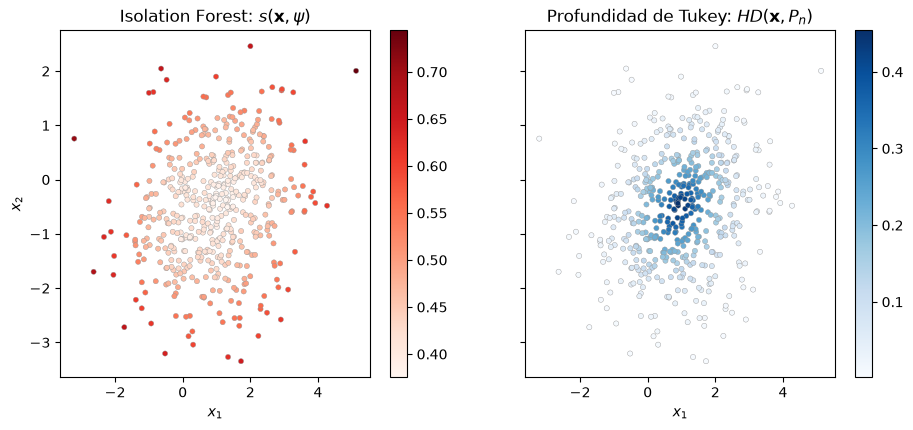

In [84]:
dibujar_mapas(datos, s_datos, hd_datos, "../figures/01.1_mapas_s_hd.pdf")

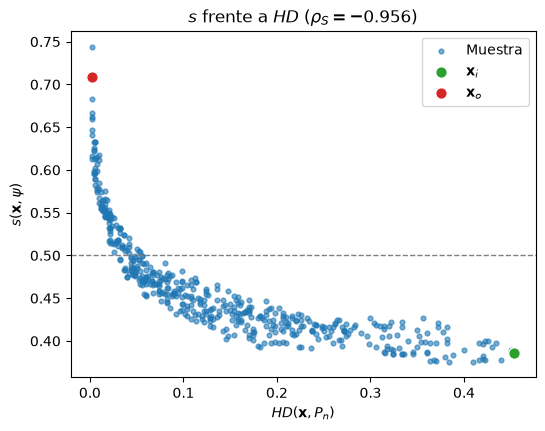

In [85]:
rho = dibujar_s_frente_hd(s_datos, hd_datos, "../figures/01.1_s_frente_hd.pdf")

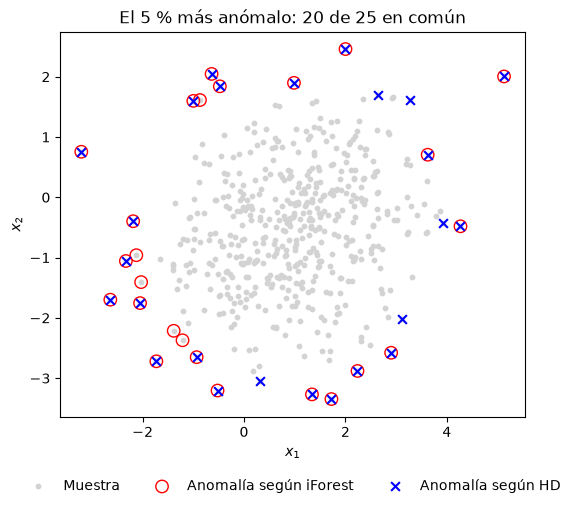

In [86]:
comunes, k = anomalias_comunes(datos, s_datos, hd_datos, "../figures/01.1_anomalias.pdf")

### Observaciones del Ejemplo 1

- La correlación de Spearman entre $s$ y $HD$ es $\rho_S = -0.956$: la relación es claramente
  monótona decreciente.
- En los extremos ambos métodos coinciden: $\mathbf{x}_i$ es la observación más profunda de la muestra
  ($HD = 0.454$) y tiene una de las puntuaciones más bajas ($s = 0.386$), mientras que $\mathbf{x}_o$
  tiene profundidad mínima ($HD = 0.002$) y puntuación alta ($s = 0.709$).
- La relación no es lineal: para $HD \gtrsim 0.2$ la puntuación apenas varía, mientras que cerca de
  $HD = 0$ crece rápidamente. Isolation Forest distingue bien las observaciones periféricas pero
  ordena peor las centrales, donde la profundidad de Tukey sigue discriminando.
- De las $25$ observaciones menos profundas, $20$ están también entre las $25$ de mayor puntuación.
  Las diferencias aparecen en el borde de la nube, donde las diferencias entre observaciones son
  pequeñas.

## Ejemplo 2 - Normal bivariante con alta correlación

Generamos $n = 1000$ observaciones de una normal bivariante $N_2(\boldsymbol{\mu}, \Sigma)$ con
$$
\boldsymbol{\mu} = \begin{pmatrix} 2 \\ -1 \end{pmatrix}, \qquad
\Sigma = \begin{pmatrix} 2 & 1.2 \\ 1.2 & 1 \end{pmatrix},
$$
es decir, varianzas $2$ y $1$ y correlación $1.2/\sqrt{2} \approx 0.85$. La correlación es
intencionada: los cortes de Isolation Forest son paralelos a los ejes, mientras que la profundidad
de Tukey es afín invariante, y una distribución inclinada permite ver esa diferencia.

Para seguir dos observaciones concretas a lo largo del cuaderno elegimos, con la distancia de
Mahalanobis $d_M(\mathbf{x}) = \sqrt{(\mathbf{x}-\boldsymbol{\mu})^T \Sigma^{-1} (\mathbf{x}-\boldsymbol{\mu})}$,
la observación más central de la muestra, $\mathbf{x}_i$, y la más alejada, $\mathbf{x}_o$.

In [87]:
rng = np.random.default_rng(20261010)
mu = np.array([2.0, -1.0])
Sigma = np.array([[2.0, 1.2],
                  [1.2, 1.0]])
n = 1000
datos = rng.multivariate_normal(mu, Sigma, size=n)

Sigma_inv = np.linalg.inv(Sigma)
d_M = np.sqrt(np.einsum("ij,jk,ik->i", datos - mu, Sigma_inv, datos - mu))
i_central, i_atipico = np.argmin(d_M), np.argmax(d_M)
x_i, x_o = datos[i_central], datos[i_atipico]

print(f"x_i = ({x_i[0]:.2f}, {x_i[1]:.2f}),  d_M = {d_M[i_central]:.2f}")
print(f"x_o = ({x_o[0]:.2f}, {x_o[1]:.2f}),  d_M = {d_M[i_atipico]:.2f}")

x_i = (2.00, -0.99),  d_M = 0.01
x_o = (3.23, 1.62),  d_M = 3.66


Representamos la muestra con las elipses del $50\,\%$, $90\,\%$ y $99\,\%$ de la probabilidad
(la función `elipse` usa los nuevos $\boldsymbol{\mu}$ y $\Sigma$).

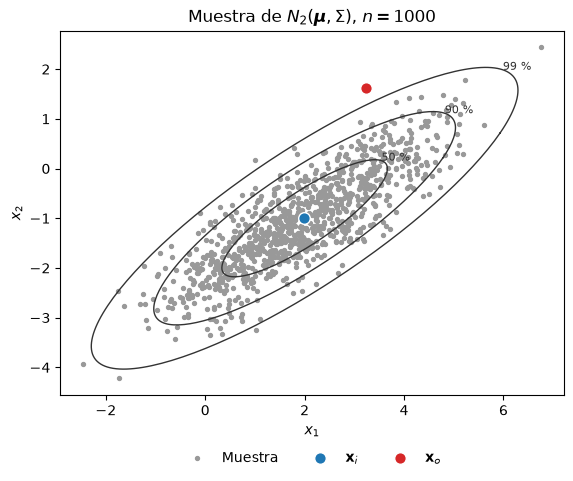

In [88]:
fig, eje = plt.subplots(figsize=(6.5, 5))
eje.scatter(datos[:, 0], datos[:, 1], s=8, c="0.6", label="Muestra")
for nivel in (0.5, 0.9, 0.99):
    e = elipse(nivel)
    eje.plot(e[:, 0], e[:, 1], color="0.2", linewidth=1)
    eje.annotate(f"{int(nivel * 100)} %", e[25], fontsize=8, color="0.2")
eje.scatter(*x_i, s=70, c="tab:blue", edgecolors="white", zorder=3, label=r"$\mathbf{x}_i$")
eje.scatter(*x_o, s=70, c="tab:red", edgecolors="white", zorder=3, label=r"$\mathbf{x}_o$")
eje.set_xlabel("$x_1$")
eje.set_ylabel("$x_2$")
eje.set_title(r"Muestra de $N_2(\boldsymbol{\mu}, \Sigma)$, $n = 1000$")
eje.set_aspect("equal")
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.savefig("../figures/01.2_datos.pdf", bbox_inches="tight")
plt.show()

### Comparación iForest vs. Halfspace Depth

En este ejemplo, vamos a hacer el cálculo directamente de ambas métricas y comparar sus resultados para el nuevo conjunto de muestras.

Construimos un bosque con los mismos parámetros que en el Ejemplo 1, $t = 100$ árboles, $\psi = 256$
y $h_{lim} = \psi - 1$, y calculamos $s(\mathbf{x},\psi)$ para las 1000 observaciones.

In [89]:
random.seed(200)
bosque = iforest(datos.tolist(), t=100, psi=psi)

E_h = np.array([longitud_media(list(x), bosque, hlim) for x in datos])
s_datos = 2 ** (-E_h / c(psi))

print(f"s en la muestra: mínimo {s_datos.min():.3f}, máximo {s_datos.max():.3f}")

s en la muestra: mínimo 0.380, máximo 0.773


In [90]:
modelo = DepthEucl().load_dataset(datos)
hd_datos = modelo.halfspace(datos, exact=True)

print(f"HD en la muestra: mínimo {hd_datos.min():.3f}, máximo {hd_datos.max():.3f}")
print(f"HD(x_i) = {hd_datos[i_central]:.3f},  s(x_i) = {s_datos[i_central]:.3f}")
print(f"HD(x_o) = {hd_datos[i_atipico]:.3f},  s(x_o) = {s_datos[i_atipico]:.3f}")

HD en la muestra: mínimo 0.001, máximo 0.468
HD(x_i) = 0.452,  s(x_i) = 0.404
HD(x_o) = 0.001,  s(x_o) = 0.644


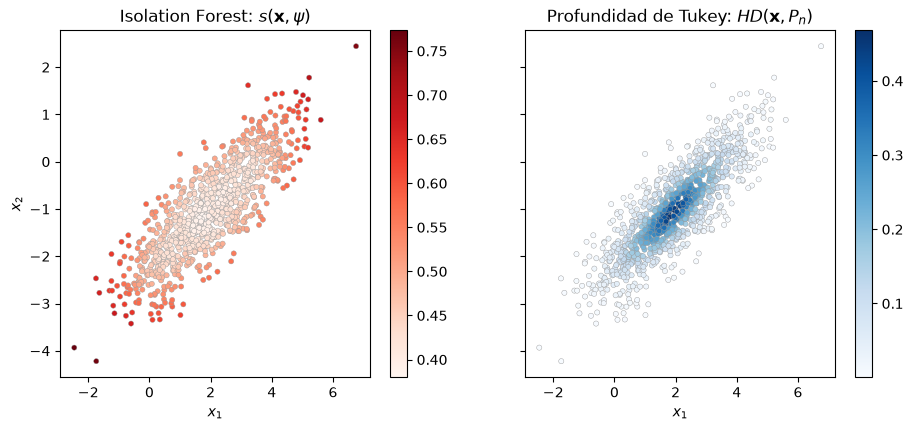

In [91]:
dibujar_mapas(datos, s_datos, hd_datos, "../figures/01.2_mapas_s_hd.pdf")

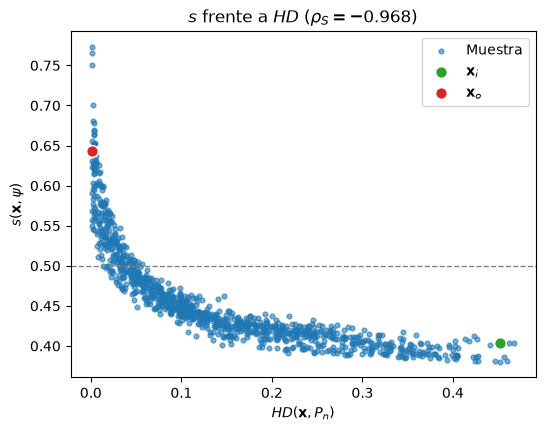

Correlación de Spearman entre s y HD: -0.968


In [92]:
rho = dibujar_s_frente_hd(s_datos, hd_datos, "../figures/01.2_s_frente_hd.pdf")
print(f"Correlación de Spearman entre s y HD: {rho:.3f}")

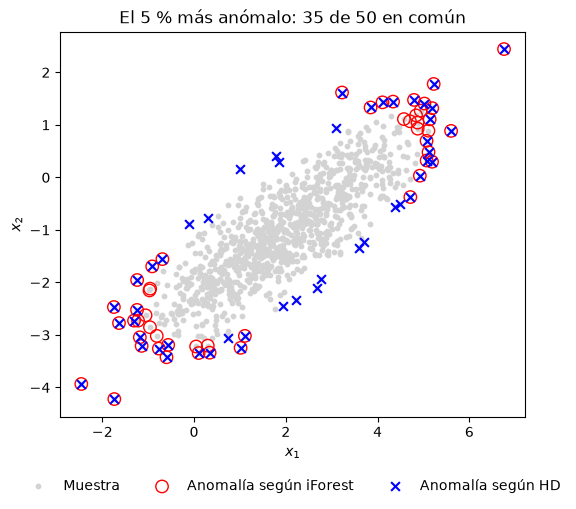

In [93]:
comunes, k = anomalias_comunes(datos, s_datos, hd_datos, "../figures/01.2_anomalias.pdf")

### Observaciones del Ejemplo 2

- La correlación de Spearman entre $s$ y $HD$ es $\rho_S = -0.966$, tan alta como en el Ejemplo 1: en
  conjunto, ambos métodos siguen ordenando las observaciones de forma parecida.
- Sin embargo, al mirar el $5\,\%$ más anómalo la coincidencia baja: $36$ de $50$ ($72\,\%$), frente al
  $80\,\%$ del Ejemplo 1. Además, el gráfico muestra un patrón claro. Las anomalías según Isolation
  Forest se concentran en los extremos del eje mayor de la elipse, mientras que las de Tukey se
  reparten por todo su contorno, también por los lados, en la dirección del eje menor.
- La explicación está en la forma de cortar: los cortes de Isolation Forest son paralelos a los ejes
  y aíslan con facilidad un punto cuyas coordenadas se salen del rango de los datos, como ocurre en
  los extremos del eje mayor. En los lados de la elipse, en cambio, cada coordenada por separado
  toma valores normales y lo atípico es su combinación, lo que los cortes paralelos a los ejes no
  detectan bien. La profundidad de Tukey es afín invariante y no depende de la orientación de la
  nube.
- La correlación de Spearman global no detecta esta diferencia, porque está dominada por las
  observaciones centrales, que son la mayoría. La diferencia está en la cola, que es justamente
  donde se decide qué es una anomalía.

**Comparación de los dos ejemplos.** Con correlación baja, Isolation Forest y la profundidad de
Tukey se comportan de forma muy parecida. Con correlación alta, el orden global se mantiene, pero
Isolation Forest deja de detectar las observaciones atípicas en la dirección del eje menor. Es una
primera situación en la que la aproximación de $HD$ mediante Isolation Forest falla de forma
sistemática.